# Do written personas give Jev more to work with?

The [persona test](persona_test.ipynb) showed Jev barely responds to trait numbers but responds strongly to stated preferences. This notebook tries a way to get those preferences at scale:

1. Draw 5 traits evenly from 0 to 1.
2. Have Claude Haiku 5.5 write them into 2 to 3 sentences, including what the person wants in a partner.
3. Test whether Jev responds to them, compared with Gaussian and uniform trait numbers.

**This is a 50-persona sample, not the final dataset.** It doesn't touch `main.db` or `personas.db`. Personas and Jev's results are saved next to this notebook, so re-running it doesn't pay again.

**What would justify generating the full 2,000:**
- **Effect size:** the persona effect is well above the 0.043 that uniform traits reached.
- **Real preferences:** the persona × target interaction is clearly above noise. A persona that just likes everybody more is no use to a matcher. It needs different people to like different targets.

## Setup

In [1]:
import json
import os
import random
import re
import statistics
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import anthropic
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "Data Generation")]

import synthetic_personas
from manager import ProfileManager
from matching import is_compatible
from models import Persona
from raters import JEV_PRICE_PER_MTOK, _call_jev, build_rater_input

PERSONAS_PATH = ROOT / "notebooks" / "written_personas_sample.json"
RESULTS_PATH = ROOT / "notebooks" / "written_persona_results.csv"
REGENERATE_PERSONAS = False  # Set to True to replace the saved personas. This costs money.
RERUN_JEV = False  # Set to True to replace the saved Jev results. This costs money.

CLAUDE_MODEL = "claude-haiku-5-5"
CLAUDE_INPUT_PRICE_PER_MTOK = 0.10
CLAUDE_OUTPUT_PRICE_PER_MTOK = 0.50

SEED = 42
N_SAMPLE_PERSONAS = 50
N_RATERS = 4
N_PERSONAS = 10  # Per condition, for each rater.
N_TARGETS = 6
N_REPEATS = 6
N_WORKERS = 8

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.bottom": False,
    "ytick.left": False,
    "text.color": INK,
    "font.size": 10,
    "figure.dpi": 120,
})

## Write the personas

The persona leaves out name and gender so it can be paired with any profile in this test, and it asks for preferences that can be judged from a dating profile.

In [2]:
PERSONA_TRAITS = ("extraversion", "openness", "conscientiousness", "traditionalism", "achievement_drive")

SYSTEM_PROMPT = "You write short fictional personas for a research simulation of a dating app. Everyone in it is a simulated adult college student."

PROMPT = """Write a persona from these trait scores, each from 0 to 1, where 0.5 is about average:
{traits}

Write 2 to 3 sentences in the third person, using "they". First say what they're like. Then say specifically what they want and don't want in a partner, in ways that can be judged from a dating profile, such as interests, clubs, major, job, religion, and relationship goals. Make the preferences clear enough that they'd like some profiles and pass on others.

Don't mention the trait names or scores, or the person's name or gender. Keep it non-sexual. Reply with only the persona."""


def write_persona(client, traits):
    response = client.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=400,
        thinking={"type": "disabled"},
        output_config={"effort": "low"},
        system=SYSTEM_PROMPT,
        messages=[{"role": "user", "content": PROMPT.format(traits=json.dumps(traits))}],
    )
    if response.stop_reason != "end_turn":
        raise RuntimeError(f"Claude stopped early: {response.stop_reason}")
    text = next(block.text for block in response.content if block.type == "text").strip()
    return {
        "traits": traits,
        "description": text,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
    }


def generate_personas():
    if not (os.environ.get("ANTHROPIC_API_KEY") or os.environ.get("ANTHROPIC_AUTH_TOKEN")):
        raise RuntimeError("Set the ANTHROPIC_API_KEY environment variable first.")
    rng = random.Random(SEED)
    all_traits = [
        {trait: round(rng.uniform(0, 1), 2) for trait in PERSONA_TRAITS} for _ in range(N_SAMPLE_PERSONAS)
    ]
    client = anthropic.Anthropic(max_retries=5)
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        return list(pool.map(lambda traits: write_persona(client, traits), all_traits))


if REGENERATE_PERSONAS or not PERSONAS_PATH.exists():
    written_personas = generate_personas()
    PERSONAS_PATH.write_text(json.dumps(written_personas, indent=2))
else:
    written_personas = json.loads(PERSONAS_PATH.read_text())

claude_input = sum(p["input_tokens"] for p in written_personas)
claude_output = sum(p["output_tokens"] for p in written_personas)
per_persona_cost = (
    claude_input * CLAUDE_INPUT_PRICE_PER_MTOK + claude_output * CLAUDE_OUTPUT_PRICE_PER_MTOK
) / 1e6 / len(written_personas)
print(f"{len(written_personas)} personas: {claude_input / len(written_personas):.0f} input and {claude_output / len(written_personas):.0f} output tokens each")
print(f"Cost per persona: ${per_persona_cost:.6f}, so 2,000 cost about ${per_persona_cost * 2000:.2f}")

50 personas: 287 input and 194 output tokens each
Cost per persona: $0.000126, so 2,000 cost about $0.25


### What they look like

Check these by eye. A persona should describe someone specific and say who they would and wouldn't want.

In [3]:
def words(text):
    return set(re.findall(r"[a-z']+", text.lower()))


word_sets = [words(p["description"]) for p in written_personas]
overlaps = [
    len(a & b) / len(a | b)
    for i, a in enumerate(word_sets)
    for b in word_sets[i + 1:]
]
lengths = [len(p["description"]) for p in written_personas]
print(f"Length: {min(lengths)} to {max(lengths)} characters, mean {statistics.fmean(lengths):.0f}")
print(f"Duplicates: {len(written_personas) - len({p['description'] for p in written_personas})}")
sentence_counts = pd.Series([len(re.findall(r"[.!?](?:\s|$)", p["description"])) for p in written_personas])
print(f"Sentences: {sentence_counts.value_counts().sort_index().to_dict()}")
print(f"Word overlap between two personas: mean {statistics.fmean(overlaps):.2f}, highest {max(overlaps):.2f} (1 would be the same words)")
print()
for persona in written_personas[:6]:
    print(persona["traits"])
    print(persona["description"])
    print()

Length: 482 to 860 characters, mean 647
Duplicates: 0
Sentences: {2: 15, 3: 34, 4: 1}
Word overlap between two personas: mean 0.22, highest 0.41 (1 would be the same words)

{'extraversion': 0.64, 'openness': 0.03, 'conscientiousness': 0.28, 'traditionalism': 0.22, 'achievement_drive': 0.74}
They are an outgoing, driven college student who thrives on social energy and sets ambitious goals, though they prefer familiar routines over experimenting with unconventional lifestyles and tend to be spontaneous rather than meticulously organized. They want a partner who is career-focused and involved in campus leadership, pursuing a serious major like engineering, pre-law, or business, and who enjoys sports, debate, or student government, while they would pass on profiles that emphasize niche hobbies, art-focused or unstructured lifestyles, or stated disinterest in ambition and social life.

{'extraversion': 0.68, 'openness': 0.89, 'conscientiousness': 0.09, 'traditionalism': 0.42, 'achievement_

## Test them on Jev

Each rater keeps one profile, and every persona in every condition is shown the same targets, which gives a full persona × target grid. This separates three effects:

| Effect | Question | What it means for a matcher |
| --- | --- | --- |
| **Persona** | Do some personas like everyone more? | Little use, since it says nothing about who suits whom |
| **Target** | Are some profiles liked more by everyone? | Popularity, which a matcher can learn without personas |
| **Persona × target** | Do different personas like different targets? | **The hidden preferences a matcher needs to learn** |

Repeats of one request measure Jev's noise. All three conditions use the same Jev question, which handles both trait scores and written preferences, so only the persona differs. That question was reworded after the [persona test](persona_test.ipynb), so compare with those earlier numbers loosely.

In [4]:
def gaussian_persona(rng):
    return json.dumps({"scores": synthetic_personas.generate_scores(rng)})


def uniform_persona(rng):
    return json.dumps({
        "scores": {
            category: {trait: round(rng.uniform(0, 1), 2) for trait in traits}
            for category, traits in synthetic_personas.TRAITS.items()
        }
    })


def plan_requests(profiles):
    """Fix every request up front, so the plan doesn't depend on the order calls finish."""
    rng = random.Random(SEED)
    raters = rng.sample([p for p in profiles if p.interested_in == {"man": "women", "woman": "men"}[p.gender]], N_RATERS)
    plan = []
    for rater_index, rater in enumerate(raters):
        targets = rng.sample([p for p in profiles if is_compatible(rater, p)], N_TARGETS)
        descriptions = {
            "Gaussian": [gaussian_persona(rng) for _ in range(N_PERSONAS)],
            "Uniform": [uniform_persona(rng) for _ in range(N_PERSONAS)],
            "Written": [p["description"] for p in rng.sample(written_personas, N_PERSONAS)],
        }
        for condition, personas in descriptions.items():
            for persona_index, description in enumerate(personas):
                for target_index, target in enumerate(targets):
                    plan.append((condition, rater_index, persona_index, target_index, False, rater, description, target))
            for _ in range(N_REPEATS):
                plan.append((condition, rater_index, 0, 0, True, rater, personas[0], targets[0]))
    return plan


def rate(request):
    condition, rater_index, persona_index, target_index, repeat, rater, description, target = request
    persona = Persona(user_id=rater.user_id, description=description)
    score, raw_output = _call_jev(build_rater_input(rater, persona, target))
    return {
        "condition": condition,
        "rater": rater_index,
        "persona": persona_index,
        "target": target_index,
        "repeat": repeat,
        "like": score,
        "input_tokens": json.loads(raw_output)["input_tokens"],
    }


if RERUN_JEV or not RESULTS_PATH.exists():
    manager = ProfileManager(ROOT / "main.db", ROOT / "personas.db")
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        results = pd.DataFrame(list(pool.map(rate, plan_requests(manager.list_profiles()))))
    results.to_csv(RESULTS_PATH, index=False)
else:
    results = pd.read_csv(RESULTS_PATH)

tokens = results["input_tokens"].sum()
print(f"{len(results)} ratings, about ${tokens / 1e6 * JEV_PRICE_PER_MTOK:.3f} on Jev")
print(results.groupby("condition")["input_tokens"].mean().round(0).to_string())

792 ratings, about $0.031 on Jev
condition
Gaussian    1004.0
Uniform     1005.0
Written      775.0


## Result 1: how large is each effect?

These are SDs of the like probability, averaged over raters. **SD across personas** is the same measure as the earlier test, where uniform traits reached 0.043. Noise is subtracted from the interaction, since noise alone would make it look above zero.

In [5]:
CONDITIONS = ["Gaussian", "Uniform", "Written"]


def effects_for(cell):
    grid = cell.pivot(index="persona", columns="target", values="like")
    values = grid.values
    residuals = values - values.mean(axis=1, keepdims=True) - values.mean(axis=0, keepdims=True) + values.mean()
    n_personas, n_targets = values.shape
    interaction = np.sqrt((residuals**2).sum() / ((n_personas - 1) * (n_targets - 1)))
    return {
        "across_personas": values.std(axis=0, ddof=1).mean(),
        "persona_main": values.mean(axis=1).std(ddof=1),
        "target_main": values.mean(axis=0).std(ddof=1),
        "raw_interaction": interaction,
    }


grid_results = results[~results["repeat"]]
noise_by_cell = results[results["repeat"]].groupby(["condition", "rater"])["like"].std()
rows = []
for (condition, rater), cell in grid_results.groupby(["condition", "rater"]):
    effects = effects_for(cell)
    noise = noise_by_cell.loc[(condition, rater)]
    effects["noise"] = noise
    effects["interaction"] = np.sqrt(max(effects["raw_interaction"] ** 2 - noise**2, 0))
    rows.append({"condition": condition, "rater": rater, **effects})
effects = pd.DataFrame(rows)

summary = effects.groupby("condition")[["across_personas", "persona_main", "target_main", "interaction", "noise"]].mean().loc[CONDITIONS]
summary["mean_like"] = grid_results.groupby("condition")["like"].mean()
summary["sd_like"] = grid_results.groupby("condition")["like"].std()
summary.round(3)

,across_personas,persona_main,target_main,interaction,noise,mean_like,sd_like
condition,,,,,,,
Gaussian,0.034,0.030,0.100,0.011,0.010,0.579,0.149
Uniform,0.044,0.042,0.093,0.015,0.010,0.565,0.144
Written,0.166,0.106,0.126,0.144,0.015,0.418,0.242


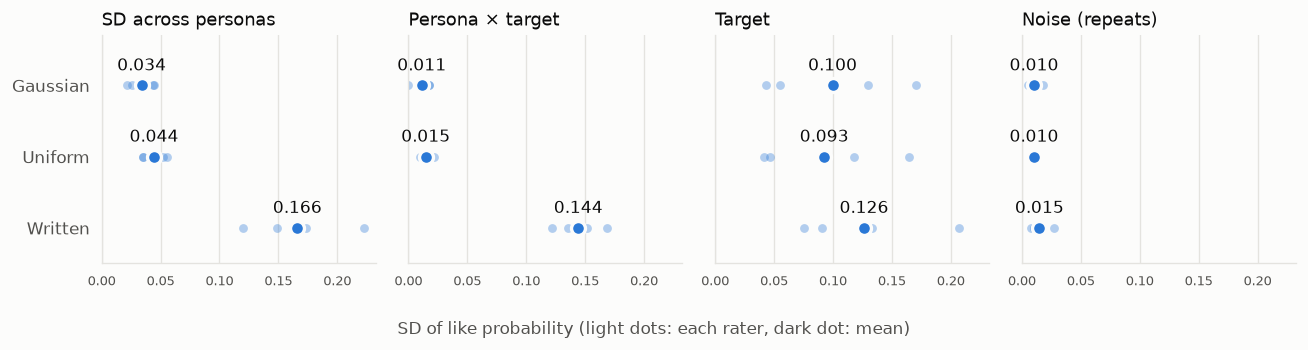

In [6]:
panels = [
    ("across_personas", "SD across personas"),
    ("interaction", "Persona × target"),
    ("target_main", "Target"),
    ("noise", "Noise (repeats)"),
]
fig, axes = plt.subplots(1, len(panels), figsize=(11, 2.9), sharey=True, sharex=True)
positions = np.arange(len(CONDITIONS))[::-1]
for ax, (column, title) in zip(axes, panels):
    for position, condition in zip(positions, CONDITIONS):
        values = effects[effects["condition"] == condition][column]
        ax.scatter(values, [position] * len(values), s=28, color=BLUE, alpha=0.35, linewidths=0)
        ax.scatter(values.mean(), position, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.annotate(f"{values.mean():.3f}", (values.mean(), position), xytext=(0, 9), textcoords="offset points", ha="center")
    ax.set_title(title)
    ax.set_xlim(left=0)
    ax.set_ylim(-0.5, len(CONDITIONS) - 0.3)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(positions, CONDITIONS)
fig.supxlabel("SD of like probability (light dots: each rater, dark dot: mean)", color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

### Compared with Gaussian and uniform, per rater

With 4 raters, treat these as a rough guide rather than a formal test.

In [7]:
wide = effects.pivot(index="rater", columns="condition", values=["across_personas", "interaction"])
comparison = []
for measure in ["across_personas", "interaction"]:
    for baseline in ["Gaussian", "Uniform"]:
        difference = wide[measure]["Written"] - wide[measure][baseline]
        comparison.append({
            "measure": measure,
            "written_versus": baseline,
            "mean_difference": difference.mean(),
            "raters_higher": f"{int((difference > 0).sum())} of {N_RATERS}",
        })
pd.DataFrame(comparison).round(3)

,measure,written_versus,mean_difference,raters_higher
0,across_personas,Gaussian,0.132,4 of 4
1,across_personas,Uniform,0.122,4 of 4
2,interaction,Gaussian,0.133,4 of 4
3,interaction,Uniform,0.130,4 of 4


## Result 2: do written personas widen the range of scores?

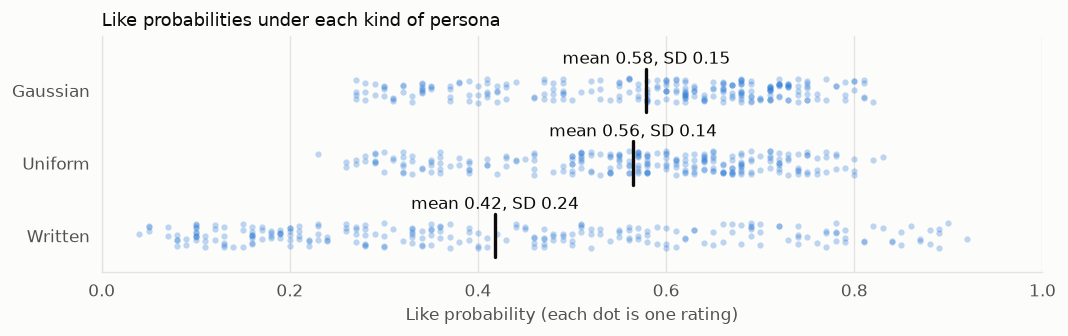

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.9))
jitter = np.random.default_rng(SEED)
for position, condition in zip(positions, CONDITIONS):
    values = grid_results[grid_results["condition"] == condition]["like"]
    ax.scatter(values, position + jitter.uniform(-0.17, 0.17, len(values)), s=14, color=BLUE, alpha=0.3, linewidths=0)
    ax.plot([values.mean()] * 2, [position - 0.3, position + 0.3], color=INK, linewidth=2, solid_capstyle="round")
    ax.annotate(f"mean {values.mean():.2f}, SD {values.std():.2f}", (values.mean(), position + 0.3), xytext=(0, 3), textcoords="offset points", ha="center")
ax.set_yticks(positions, CONDITIONS)
ax.set_ylim(-0.5, len(CONDITIONS) - 0.25)
ax.set_xlim(0, 1)
ax.set_xlabel("Like probability (each dot is one rating)")
ax.grid(axis="y", visible=False)
ax.set_title("Like probabilities under each kind of persona")
fig.tight_layout()
plt.show()

## Result 3: do different personas like different targets?

This shows every persona × target rating for one rater. Whole rows or columns sharing a shade mean a persona or target effect. Patchy cells that differ by both row and column mean real differences in taste.

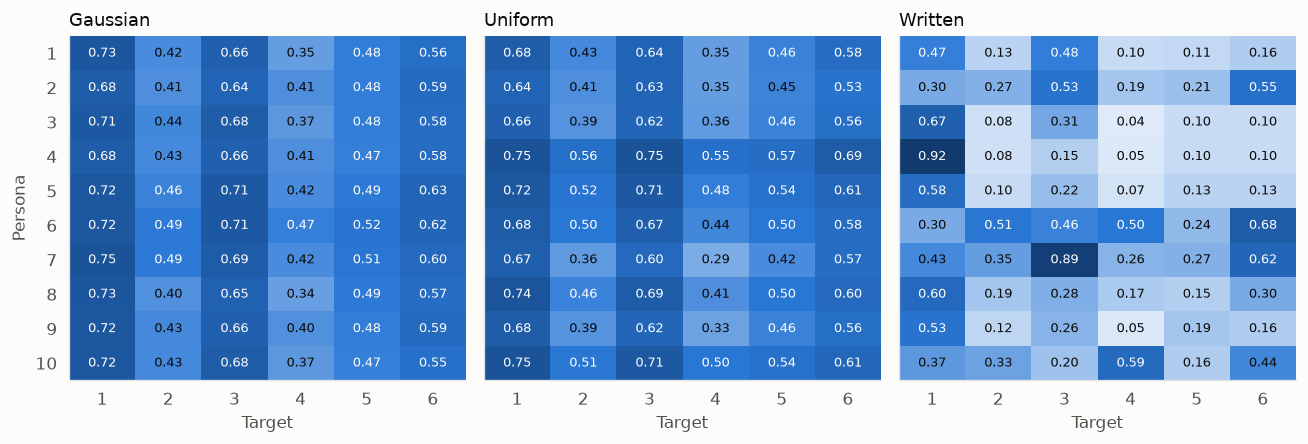

In [9]:
shades = LinearSegmentedColormap.from_list("like", ["#eef4fc", BLUE, "#0d2f5c"])
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(11, 3.8), sharey=True)
for ax, condition in zip(axes, CONDITIONS):
    cell = grid_results[(grid_results["condition"] == condition) & (grid_results["rater"] == 0)]
    grid = cell.pivot(index="persona", columns="target", values="like")
    ax.imshow(grid.values, cmap=shades, vmin=0, vmax=1, aspect="auto")
    for (row, column), value in np.ndenumerate(grid.values):
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color=SURFACE if value > 0.45 else INK)
    ax.set_title(condition)
    ax.set_xlabel("Target")
    ax.set_xticks(range(N_TARGETS), range(1, N_TARGETS + 1))
    ax.grid(False)
axes[0].set_yticks(range(N_PERSONAS), range(1, N_PERSONAS + 1))
axes[0].set_ylabel("Persona")
fig.tight_layout()
plt.show()

## Result 4: do the preferences make sense?

Strong effects aren't enough, since a matcher would be learning from nonsense if they were arbitrary. Traditionalism gives a direct check: Claude was told each persona's score, so high-traditionalism personas should prefer religious targets and low-traditionalism personas should prefer non-religious ones.

This reuses the saved ratings and calls no API. Targets count as religious unless their religion is atheist, agnostic, or spiritual.

In [10]:
traits_by_description = {p["description"]: p["traits"] for p in written_personas}
profiles = ProfileManager(ROOT / "main.db", ROOT / "personas.db").list_profiles()
lookup = []
for condition, rater, persona, target, repeat, _, description, target_profile in plan_requests(profiles):
    if condition == "Written" and not repeat:
        lookup.append({
            "rater": rater,
            "persona": persona,
            "target": target,
            "traditionalism": traits_by_description[description]["traditionalism"],
            "religious_target": target_profile.religion not in ("atheist", "agnostic", "spiritual"),
        })
written = pd.DataFrame(lookup).merge(grid_results[grid_results["condition"] == "Written"], on=["rater", "persona", "target"])
written["traditionalism_group"] = pd.cut(written["traditionalism"], [-1, 0.33, 0.66, 2], labels=["Low", "Middle", "High"])
sense_check = written.pivot_table(index="traditionalism_group", columns="religious_target", values="like", observed=False)
sense_check.columns = ["Non-religious target", "Religious target"]
sense_check["religious_minus_non_religious"] = sense_check["Religious target"] - sense_check["Non-religious target"]
print(f"{len(written)} ratings. Raters with both kinds of target: {written.groupby('rater')['religious_target'].nunique().eq(2).sum()} of {N_RATERS}")
sense_check.round(3)

240 ratings. Raters with both kinds of target: 3 of 4


,Non-religious target,Religious target,religious_minus_non_religious
traditionalism_group,,,
Low,0.448,0.359,-0.089
Middle,0.448,0.472,0.024
High,0.289,0.439,0.150


## What this shows

**Written personas pass both tests, so they're worth generating at full scale.**

| Measure | Gaussian | Uniform | Written |
| --- | --- | --- | --- |
| SD across personas | 0.034 | 0.044 | **0.166** |
| Persona × target interaction | 0.011 | 0.015 | **0.144** |
| Noise (repeats) | 0.010 | 0.010 | 0.015 |
| Ratings at 0.3 or below | 5% | 6% | **40%** |
| Ratings at 0.7 or above | 25% | 18% | 17% |

- **Effect size:** the persona effect is nearly 4 times the uniform result, and it's higher for all 4 raters.
- **Real preferences:** the interaction is about 10 times noise. With trait numbers it was barely above noise. Different personas now like different people, which is what a matcher has to learn.
- **The preferences make sense:** high-traditionalism personas favor religious targets by 0.15, and low-traditionalism personas favor non-religious targets by 0.09. Each rater with both kinds of target showed this pattern.
- **Firmer answers:** Jev now gives clear no's, so fewer ratings sit in the unsure range between 0.3 and 0.7.
- **Cost:** about $0.25 for 2,000 personas at this length. Written personas are also shorter than trait numbers, at about 775 Jev tokens per rating instead of 1,005.

**Limits of this test:**
- It's a small sample: 4 raters, with 10 personas and 6 targets each. One rater's targets were all religious, so the sense check rests on 3 raters. Treat the gaps as a direction rather than a precise size.
- Each persona was written without seeing a profile, so a persona can conflict with the profile it's paired with, such as an atheist who wants a religious lifestyle.
- Many personas mention things profiles don't show, such as five-year plans or politics. Jev has to judge those from indirect clues or ignore them.
- Scores lean lower, with a mean of 0.42 against about 0.57, and that could affect a like rate if you draw simulated swipes from them.
- These are still Jev's estimates of made-up people, not real behavior.